# Sprint 1: Data Understanding & Preprocessing

## Objective

The goal of **Sprint 1** is to transform the raw **Steel Industry Energy Consumption** dataset into a clean, well-structured, and model-ready dataset for predicting energy consumption.

This sprint includes:

- Loading and inspecting the dataset
- Understanding the dataset structure and feature definitions
- Assessing data quality (missing values, duplicates, and inconsistent records)
- Performing Exploratory Data Analysis (EDA)
- Analyzing feature distributions and relationships with the target variable
- Detecting and handling outliers
- Engineering relevant features (if required)
- Encoding categorical variables
- Splitting the dataset into training, validation, and testing sets
- Scaling numerical features where appropriate
- Building a reusable preprocessing pipeline

The output of this sprint will be a cleaned, preprocessed, and reproducible dataset that serves as the foundation for model development and evaluation in **Sprint 2**.

In [206]:
# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

# Data Manipulation
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns


# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Plot Settings
plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Display Options
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 10)
pd.set_option("display.float_format", "{:.2f}".format)

## Step 1: Data Collection & Loading

The first step is to load the Steel Industry Energy Consumption dataset and perform an initial validation to ensure it has been imported correctly.

In [207]:
# Load Dataset
df = pd.read_csv("../dataset/raw/Steel_industry_data.csv")

In [208]:
# Display the first five rows
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.00,0.00,73.21,100.00,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.00,0.00,66.77,100.00,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.00,0.00,70.28,100.00,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.00,0.00,68.09,100.00,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.00,0.00,64.72,100.00,4500,Weekday,Monday,Light_Load


In [209]:
# Display the last five rows
df.tail()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
35035,31/12/2018 23:00,3.85,4.86,0.00,0.00,62.10,100.00,82800,Weekday,Monday,Light_Load
35036,31/12/2018 23:15,3.74,3.74,0.00,0.00,70.71,100.00,83700,Weekday,Monday,Light_Load
35037,31/12/2018 23:30,3.78,3.17,0.07,0.00,76.62,99.98,84600,Weekday,Monday,Light_Load
35038,31/12/2018 23:45,3.78,3.06,0.11,0.00,77.72,99.96,85500,Weekday,Monday,Light_Load
35039,31/12/2018 00:00,3.67,3.02,0.07,0.00,77.22,99.98,0,Weekday,Monday,Light_Load


In [210]:
#Shape
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

Rows    : 35040
Columns : 11


In [211]:
# Display column names
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

1. date
2. Usage_kWh
3. Lagging_Current_Reactive.Power_kVarh
4. Leading_Current_Reactive_Power_kVarh
5. CO2(tCO2)
6. Lagging_Current_Power_Factor
7. Leading_Current_Power_Factor
8. NSM
9. WeekStatus
10. Day_of_week
11. Load_Type


In [212]:
# Define the target variable
target = "Usage_kWh"

print(f"Target Variable: {target}")

Target Variable: Usage_kWh


In [213]:
# Display feature columns
features = df.drop(columns=target).columns.tolist()

print("Feature Columns:\n")

for i, feature in enumerate(features, start=1):
    print(f"{i}. {feature}")

Feature Columns:

1. date
2. Lagging_Current_Reactive.Power_kVarh
3. Leading_Current_Reactive_Power_kVarh
4. CO2(tCO2)
5. Lagging_Current_Power_Factor
6. Leading_Current_Power_Factor
7. NSM
8. WeekStatus
9. Day_of_week
10. Load_Type


In [214]:
# Dataset Summary
print("DATASET SUMMARY")
print(f"Dataset Shape      : {df.shape}")
print(f"Number of Features : {len(features)}")
print(f"Target Variable    : {target}")

DATASET SUMMARY
Dataset Shape      : (35040, 11)
Number of Features : 10
Target Variable    : Usage_kWh


## Step 2: Initial Data Inspection

After loading the dataset, the next step is to inspect its structure and contents. This helps identify data quality issues such as missing values, incorrect data types, duplicate records, and inconsistencies.

In [215]:
# Display the first five records
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.00,0.00,73.21,100.00,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.00,0.00,66.77,100.00,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.00,0.00,70.28,100.00,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.00,0.00,68.09,100.00,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.00,0.00,64.72,100.00,4500,Weekday,Monday,Light_Load


In [216]:
# Display five random records
df.sample(5, random_state=42)

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
11356,29/04/2018 07:15,2.88,3.82,0.00,0.00,60.20,100.00,26100,Weekend,Sunday,Light_Load
26543,04/10/2018 12:00,60.77,48.02,0.00,0.03,78.46,100.00,43200,Weekday,Thursday,Maximum_Load
2445,26/01/2018 11:30,120.42,59.65,0.00,0.06,89.61,100.00,41400,Weekday,Friday,Maximum_Load
14649,02/06/2018 14:30,3.13,0.00,16.60,0.00,100.00,18.53,52200,Weekend,Saturday,Light_Load
32699,07/12/2018 15:00,58.86,20.99,0.00,0.03,94.19,100.00,54000,Weekday,Friday,Medium_Load


In [217]:
# Display dataset dimensions
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

Rows    : 35040
Columns : 11


In [218]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  object 
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-null  float64
 7   NSM                                   35040 non-null  int64  
 8   WeekStatus                            35040 non-null  object 
 9   Day_of_week                           35040 non-null  object 
 10  Load_Type                             35040 non-null  object 
dtypes: float64(6), 

In [219]:
# Summary statistics for numerical features
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Usage_kWh,35040.00,27.39,33.44,0.00,3.20,4.57,51.24,157.18
Lagging_Current_Reactive.Power_kVarh,35040.00,13.04,16.31,0.00,2.30,5.00,22.64,96.91
Leading_Current_Reactive_Power_kVarh,35040.00,3.87,7.42,0.00,0.00,0.00,2.09,27.76
CO2(tCO2),35040.00,0.01,0.02,0.00,0.00,0.00,0.02,0.07
Lagging_Current_Power_Factor,35040.00,80.58,18.92,0.00,63.32,87.96,99.02,100.00
Leading_Current_Power_Factor,35040.00,84.37,30.46,0.00,99.70,100.00,100.00,100.00
NSM,35040.00,42750.00,24940.53,0.00,21375.00,42750.00,64125.00,85500.00


In [220]:
# Summary statistics for all columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,35040,35040,01/01/2018 00:15,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Usage_kWh,35040.00,NaN,NaN,NaN,27.39,33.44,0.00,3.20,4.57,51.24,157.18
Lagging_Current_Reactive.Power_kVarh,35040.00,NaN,NaN,NaN,13.04,16.31,0.00,2.30,5.00,22.64,96.91
Leading_Current_Reactive_Power_kVarh,35040.00,NaN,NaN,NaN,3.87,7.42,0.00,0.00,0.00,2.09,27.76
CO2(tCO2),35040.00,NaN,NaN,NaN,0.01,0.02,0.00,0.00,0.00,0.02,0.07
...,...,...,...,...,...,...,...,...,...,...,...
Leading_Current_Power_Factor,35040.00,NaN,NaN,NaN,84.37,30.46,0.00,99.70,100.00,100.00,100.00
NSM,35040.00,NaN,NaN,NaN,42750.00,24940.53,0.00,21375.00,42750.00,64125.00,85500.00
WeekStatus,35040,2,Weekday,25056,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Day_of_week,35040,7,Monday,5088,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [221]:
# Display data types
df.dtypes

date                                     object
Usage_kWh                               float64
Lagging_Current_Reactive.Power_kVarh    float64
Leading_Current_Reactive_Power_kVarh    float64
CO2(tCO2)                               float64
                                         ...   
Leading_Current_Power_Factor            float64
NSM                                       int64
WeekStatus                               object
Day_of_week                              object
Load_Type                                object
Length: 11, dtype: object

In [222]:
# Count missing values
df.isnull().sum()

date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
                                       ..
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
Length: 11, dtype: int64

In [223]:
# Percentage of missing values
(df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

date                                   0.00
Usage_kWh                              0.00
Lagging_Current_Reactive.Power_kVarh   0.00
Leading_Current_Reactive_Power_kVarh   0.00
CO2(tCO2)                              0.00
                                       ... 
Leading_Current_Power_Factor           0.00
NSM                                    0.00
WeekStatus                             0.00
Day_of_week                            0.00
Load_Type                              0.00
Length: 11, dtype: float64

In [224]:
# Count duplicate records
print(f"Duplicate Records: {df.duplicated().sum()}")

Duplicate Records: 0


In [225]:
# Number of unique values in each column
df.nunique().sort_values()

WeekStatus                                  2
Load_Type                                   3
Day_of_week                                 7
CO2(tCO2)                                   8
NSM                                        96
                                        ...  
Lagging_Current_Reactive.Power_kVarh     1954
Usage_kWh                                3343
Leading_Current_Power_Factor             3366
Lagging_Current_Power_Factor             5079
date                                    35040
Length: 11, dtype: int64

In [226]:
# Categorical Columns (excluding date)
categorical_columns = ["WeekStatus", "Day_of_week", "Load_Type"]

for column in categorical_columns:
    print(f"\n{column}")
    print("-" * len(column))
    print(df[column].value_counts())


WeekStatus
----------
WeekStatus
Weekday    25056
Weekend     9984
Name: count, dtype: int64

Day_of_week
-----------
Day_of_week
Monday       5088
Tuesday      4992
Wednesday    4992
Thursday     4992
Friday       4992
Saturday     4992
Sunday       4992
Name: count, dtype: int64

Load_Type
---------
Load_Type
Light_Load      18072
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64


In [227]:
# Data Quality Summary
data_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing (%)": (df.isnull().sum() / len(df) * 100).round(2),
    "Unique Values": df.nunique()
})

data_summary

,Data Type,Missing Values,Missing (%),Unique Values
date,object,0,0.00,35040
Usage_kWh,float64,0,0.00,3343
Lagging_Current_Reactive.Power_kVarh,float64,0,0.00,1954
Leading_Current_Reactive_Power_kVarh,float64,0,0.00,768
CO2(tCO2),float64,0,0.00,8
...,...,...,...,...
Leading_Current_Power_Factor,float64,0,0.00,3366
NSM,int64,0,0.00,96
WeekStatus,object,0,0.00,2
Day_of_week,object,0,0.00,7


### Observations

- The dataset contains **35,040 records**, representing energy consumption measurements collected at **15-minute intervals** throughout the year 2018.
- The **`date`** column contains unique timestamps, indicating there are no duplicate time entries.
- **`WeekStatus`** consists of two categories:
  - **Weekday:** 25,056 observations
  - **Weekend:** 9,984 observations
- **`Day_of_week`** contains all seven days of the week with an almost uniform distribution.
- **`Load_Type`** has three operating conditions:
  - **Light_Load:** 18,072 observations
  - **Medium_Load:** 9,696 observations
  - **Maximum_Load:** 7,272 observations
- No unexpected categories or inconsistencies were observed in the categorical features.
- The categorical variables appear suitable for encoding during the preprocessing stage.

# Step 3: Data Cleaning

The objective of this step is to improve the overall quality of the dataset by identifying and resolving issues that may negatively impact model performance.


In [228]:
# Standardize column names
df.columns = (
    df.columns
      .str.strip()
      .str.lower()
      .str.replace(" ", "_")
      .str.replace(".", "_", regex=False)
)

df.columns.tolist()

['date',
 'usage_kwh',
 'lagging_current_reactive_power_kvarh',
 'leading_current_reactive_power_kvarh',
 'co2(tco2)',
 'lagging_current_power_factor',
 'leading_current_power_factor',
 'nsm',
 'weekstatus',
 'day_of_week',
 'load_type']

In [229]:
# Rename column
df = df.rename(columns={"co2(tco2)": "co2_emissions"})

# Rearrange columns
df = df[
    [
        "date",
        "weekstatus",
        "day_of_week",
        "nsm",
        "load_type",
        "lagging_current_reactive_power_kvarh",
        "leading_current_reactive_power_kvarh",
        "lagging_current_power_factor",
        "leading_current_power_factor",
        "co2_emissions",
        "usage_kwh"
    ]
]

# Verify the new column order
df.head()

,date,weekstatus,day_of_week,nsm,load_type,lagging_current_reactive_power_kvarh,leading_current_reactive_power_kvarh,lagging_current_power_factor,leading_current_power_factor,co2_emissions,usage_kwh
0,01/01/2018 00:15,Weekday,Monday,900,Light_Load,2.95,0.00,73.21,100.00,0.00,3.17
1,01/01/2018 00:30,Weekday,Monday,1800,Light_Load,4.46,0.00,66.77,100.00,0.00,4.00
2,01/01/2018 00:45,Weekday,Monday,2700,Light_Load,3.28,0.00,70.28,100.00,0.00,3.24
3,01/01/2018 01:00,Weekday,Monday,3600,Light_Load,3.56,0.00,68.09,100.00,0.00,3.31
4,01/01/2018 01:15,Weekday,Monday,4500,Light_Load,4.50,0.00,64.72,100.00,0.00,3.82


In [230]:
# Missing values
missing_values = df.isnull().sum()

print(missing_values)

date                                    0
weekstatus                              0
day_of_week                             0
nsm                                     0
load_type                               0
                                       ..
leading_current_reactive_power_kvarh    0
lagging_current_power_factor            0
leading_current_power_factor            0
co2_emissions                           0
usage_kwh                               0
Length: 11, dtype: int64


In [231]:
print(f"Duplicate Records Before : {df.duplicated().sum()}")

df = df.drop_duplicates()

print(f"Duplicate Records After  : {df.duplicated().sum()}")

Duplicate Records Before : 0
Duplicate Records After  : 0


In [232]:
# Convert date to datetime
df["date"] = pd.to_datetime(df["date"], dayfirst=True)

df["date"].head()

0   2018-01-01 00:15:00
1   2018-01-01 00:30:00
2   2018-01-01 00:45:00
3   2018-01-01 01:00:00
4   2018-01-01 01:15:00
Name: date, dtype: datetime64[ns]

In [233]:
print("CLEANED DATASET SUMMARY")

print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")
print(f"Missing Values : {df.isnull().sum().sum()}")
print(f"Duplicates     : {df.duplicated().sum()}")

CLEANED DATASET SUMMARY
Rows    : 35040
Columns : 11
Missing Values : 0
Duplicates     : 0


### Observations

- The dataset contains **35,040 observations** and **11 features**.
- No missing values were found across any of the columns.
- No duplicate records were detected.
- The column names were standardized to improve readability and maintain consistency.
- The `date` column was successfully converted to the `datetime` data type for easier time-based analysis and feature engineering.
- The dataset is clean, consistent, and ready for Exploratory Data Analysis (EDA) and feature engineering.

# Step 4: Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps uncover patterns, trends, anomalies, and relationships within the dataset before model development.


In [234]:
# Numerical Features
numerical_columns = df.select_dtypes(include=["number"]).columns.tolist()

# Categorical Features
categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()

# Datetime Features
datetime_columns = df.select_dtypes(include=["datetime"]).columns.tolist()

print(f"Numerical Features ({len(numerical_columns)}):")
print(numerical_columns)

print(f"\nCategorical Features ({len(categorical_columns)}):")
print(categorical_columns)

print(f"\nDatetime Features ({len(datetime_columns)}):")
print(datetime_columns)

Numerical Features (7):
['nsm', 'lagging_current_reactive_power_kvarh', 'leading_current_reactive_power_kvarh', 'lagging_current_power_factor', 'leading_current_power_factor', 'co2_emissions', 'usage_kwh']

Categorical Features (3):
['weekstatus', 'day_of_week', 'load_type']

Datetime Features (1):
['date']


## Univariate Analysis

### Distribution of numerical features

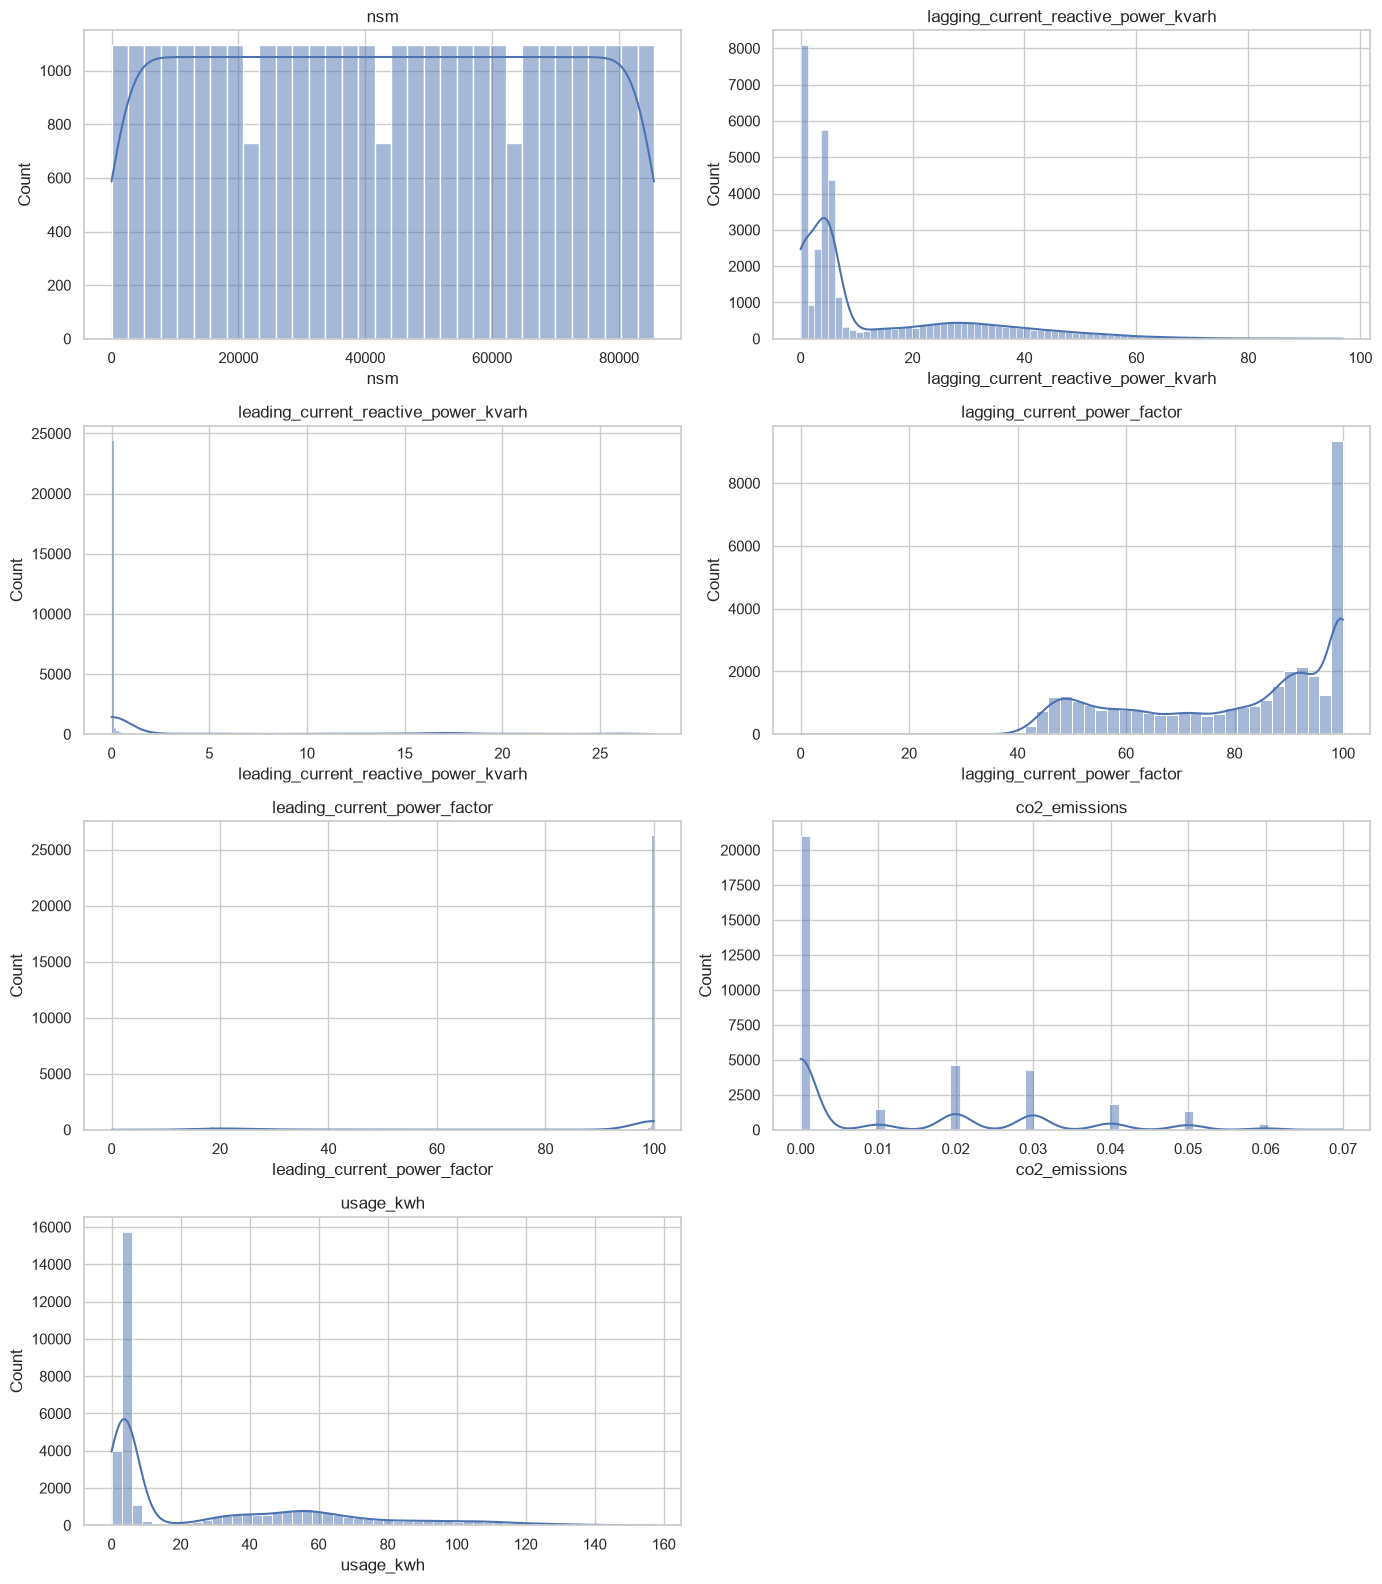

In [235]:
# Distribution of numerical features
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.ravel()

for ax, col in zip(axes, numerical_columns):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)

for ax in axes[len(numerical_columns):]:
    ax.remove()

plt.tight_layout()
plt.show()

Distribution Insights

- **nsm:** The `nsm` feature is nearly uniformly distributed, indicating that observations are evenly recorded across all time intervals of the day.

- **lagging_current_reactive_power_kvarh:** The distribution is highly right-skewed, with most observations at low values and a few high reactive power consumption events.

- **leading_current_reactive_power_kvarh:** The feature is extremely concentrated near zero, indicating that leading reactive power is minimal for most observations.

- **lagging_current_power_factor:** Most values are concentrated between 90 and 100, suggesting that the system generally operates with a high lagging power factor.

- **leading_current_power_factor:** The feature is heavily concentrated at 100, indicating an almost constant leading power factor with very little variation.

- **co2_emissions:** The distribution is right-skewed with most emissions close to zero and a few distinct peaks corresponding to higher energy usage.

- **usage_kwh:** The feature exhibits a strong right-skewed distribution, with low energy consumption dominating and occasional periods of high electricity usage.

### Boxplots for numerical features

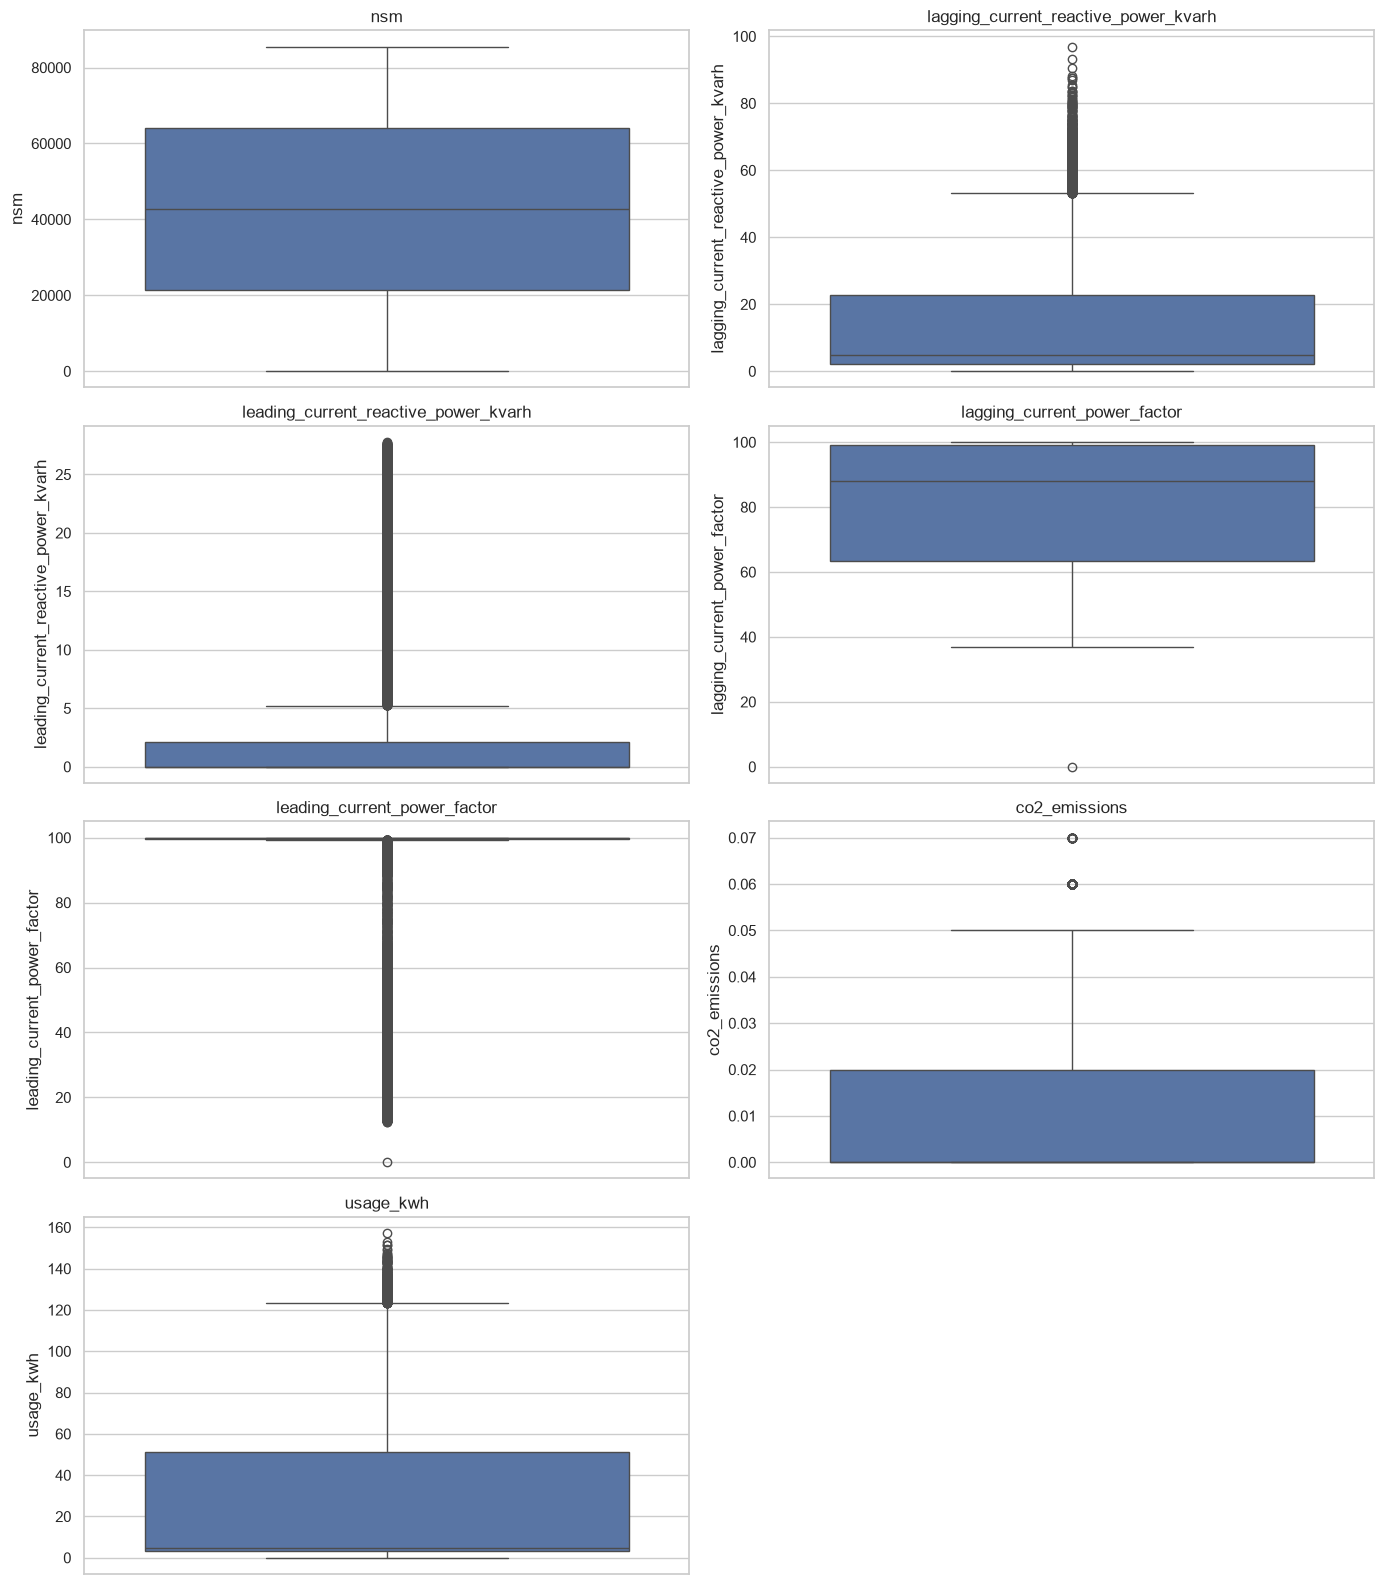

In [236]:
# Boxplots for numerical features
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.ravel()

for ax, col in zip(axes, numerical_columns):
    sns.boxplot(df[col], ax=ax)
    ax.set_title(col)

for ax in axes[len(numerical_columns):]:
    ax.remove()

plt.tight_layout()
plt.show()

Boxplot Insights

- **nsm:** The `nsm` feature shows no significant outliers, indicating a well-distributed and balanced time index.

- **lagging_current_reactive_power_kvarh:** The feature contains numerous upper-end outliers, suggesting occasional periods of unusually high lagging reactive power consumption.

- **leading_current_reactive_power_kvarh:** The feature exhibits many upper outliers, with most observations clustered near zero and a few high reactive power values.

- **lagging_current_power_factor:** The distribution contains a few lower-end outliers, while most observations are concentrated at high power factor values.

- **leading_current_power_factor:** The feature shows several lower-end outliers despite most observations being concentrated close to a power factor of 100.

- **co2_emissions:** A few upper-end outliers are present, indicating occasional periods of higher CO₂ emissions compared to typical operating conditions.

- **usage_kwh:** The feature contains numerous upper-end outliers, representing occasional instances of significantly higher energy consumption.

### Summary Statistics


In [237]:
#Summary Statistics
df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
nsm,35040.00,42750.00,24940.53,0.00,21375.00,42750.00,64125.00,85500.00
lagging_current_reactive_power_kvarh,35040.00,13.04,16.31,0.00,2.30,5.00,22.64,96.91
leading_current_reactive_power_kvarh,35040.00,3.87,7.42,0.00,0.00,0.00,2.09,27.76
lagging_current_power_factor,35040.00,80.58,18.92,0.00,63.32,87.96,99.02,100.00
leading_current_power_factor,35040.00,84.37,30.46,0.00,99.70,100.00,100.00,100.00
co2_emissions,35040.00,0.01,0.02,0.00,0.00,0.00,0.02,0.07
usage_kwh,35040.00,27.39,33.44,0.00,3.20,4.57,51.24,157.18


Statistical Summary Insights

- **nsm:** The feature is evenly distributed across the day with a median of **42,750 seconds** and no noticeable skewness.

- **lagging_current_reactive_power_kvarh:** The mean (**13.04**) is much higher than the median (**5.00**), indicating a positively skewed distribution with high-value observations.

- **leading_current_reactive_power_kvarh:** The median is **0.00** while the mean is **3.87**, showing that most values are zero with a few larger observations causing strong right skewness.

- **lagging_current_power_factor:** The median (**87.96**) is higher than the mean (**80.58**), indicating that most observations have a high power factor with a few lower values reducing the average.

- **leading_current_power_factor:** The median and upper quartiles are **100**, indicating that the feature is nearly constant with very little variation.

- **co2_emissions:** The median is **0.00** and the mean is **0.01**, suggesting that CO₂ emissions are generally very low with occasional higher emission values.

- **usage_kwh:** The mean (**27.39**) is substantially higher than the median (**4.57**), indicating a highly right-skewed distribution with occasional periods of high energy consumption.

### Skewness

In [238]:
#Skewness
skewness = df[numerical_columns].skew().sort_values(ascending=False)
skewness

leading_current_reactive_power_kvarh    1.73
lagging_current_reactive_power_kvarh    1.44
usage_kwh                               1.20
co2_emissions                           1.15
nsm                                     0.00
lagging_current_power_factor           -0.61
leading_current_power_factor           -1.51
dtype: float64

Skewness Insights

- **leading_current_reactive_power_kvarh (1.73):** The feature is highly positively skewed, with most values near zero and a few large observations.

- **lagging_current_reactive_power_kvarh (1.44):** The feature is positively skewed, indicating that high reactive power values occur infrequently.

- **usage_kwh (1.20):** The feature is positively skewed, with most observations representing low energy consumption and a few high-usage periods.

- **co2_emissions (1.15):** The feature is positively skewed, suggesting that low emissions dominate while higher emission values are relatively rare.

- **nsm (0.00):** The feature is symmetric with virtually no skewness, indicating an approximately uniform distribution.

- **lagging_current_power_factor (-0.61):** The feature is moderately negatively skewed, with most observations concentrated at higher power factor values.

- **leading_current_power_factor (-1.51):** The feature is highly negatively skewed, with the majority of observations clustered near the maximum value of 100.

### Categorical Distribution

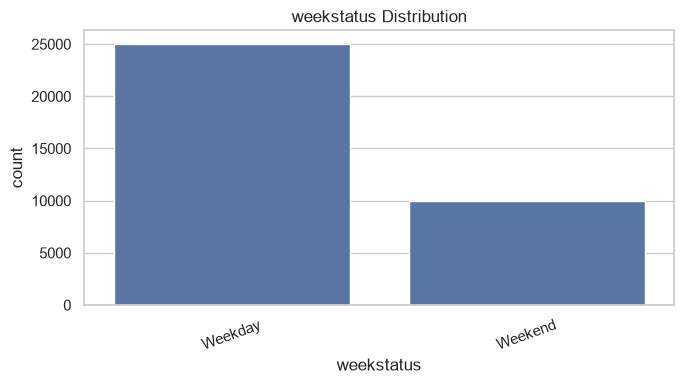

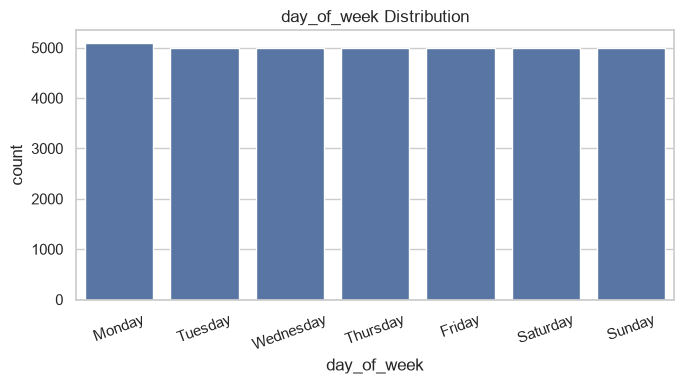

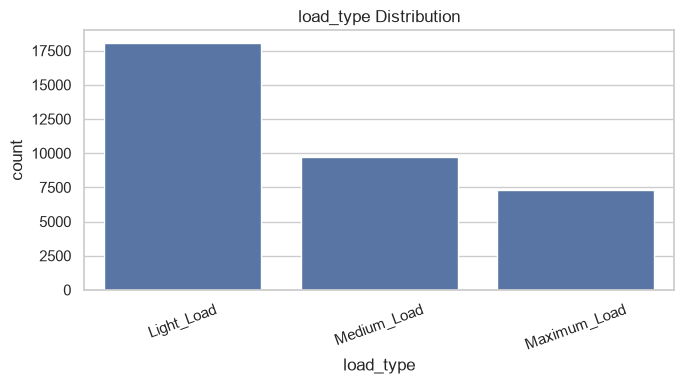

In [239]:
#Categorical Distribution
for column in categorical_columns:
    plt.figure(figsize=(7,4))
    sns.countplot(data=df, x=column)
    plt.title(f"{column} Distribution")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

Categorical Feature Insights

- **weekstatus:** The dataset contains substantially more **Weekday** observations than **Weekend** observations, reflecting the natural distribution of weekdays and weekends.

- **day_of_week:** All seven days have nearly equal numbers of observations, indicating a balanced distribution with no missing or overrepresented days.

- **load_type:** **Light_Load** is the most frequent category, followed by **Medium_Load** and **Maximum_Load**, suggesting that the system operates under lighter loads for most of the observed period.

### Distribution of Target Variable

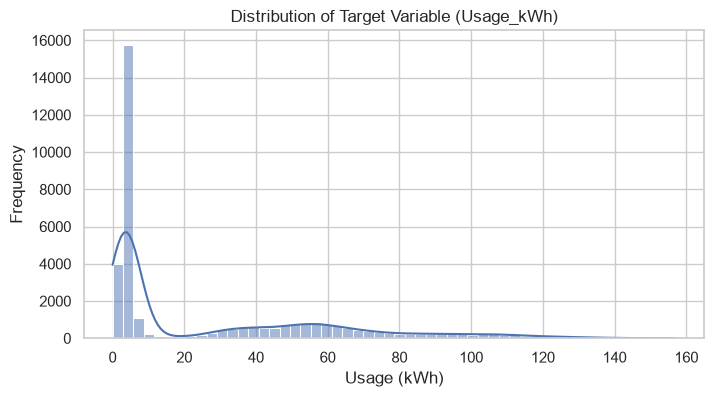

In [240]:
#Distribution of Target Variable
plt.figure(figsize=(8,4))

sns.histplot(df["usage_kwh"], kde=True)

plt.title("Distribution of Target Variable (Usage_kWh)")
plt.xlabel("Usage (kWh)")
plt.ylabel("Frequency")

plt.show()

Target Variable (`usage_kwh`) Distribution Insights

- The target variable exhibits a **highly right-skewed distribution**, with the majority of observations concentrated at lower energy consumption values.

- Most energy usage values are below **10 kWh**, while relatively few observations extend to higher consumption levels.

- A long right tail reaching approximately **160 kWh** indicates the presence of occasional high-energy consumption periods.

- The distribution is **non-normal** and contains several high-value observations that may represent peak operational loads.

- Overall, the distribution suggests that the dataset is dominated by **low energy consumption events**, with infrequent but significant spikes in electricity usage.

## Bivariate Analysis

### Coorelation with Target

In [241]:
#Coorelation with Target
correlation = (df[numerical_columns].corr()["usage_kwh"].sort_values(ascending=False))

correlation

usage_kwh                               1.00
co2_emissions                           0.99
lagging_current_reactive_power_kvarh    0.90
lagging_current_power_factor            0.39
leading_current_power_factor            0.35
nsm                                     0.23
leading_current_reactive_power_kvarh   -0.32
Name: usage_kwh, dtype: float64

Correlation with `usage_kwh`

- **co2_emissions (0.99):** Shows an extremely strong positive correlation with `usage_kwh`, indicating that CO₂ emissions increase almost proportionally with energy consumption.

- **lagging_current_reactive_power_kvarh (0.90):** Exhibits a very strong positive correlation, suggesting that higher energy usage is associated with increased lagging reactive power.

- **lagging_current_power_factor (0.39):** Shows a weak-to-moderate positive correlation, indicating a slight tendency for the lagging power factor to improve as energy consumption increases.

- **leading_current_power_factor (0.35):** Has a weak positive correlation with `usage_kwh`, suggesting only a limited linear relationship.

- **nsm (0.23):** Displays a weak positive correlation, indicating that the time of day has only a small influence on energy consumption.

- **leading_current_reactive_power_kvarh (-0.32):** Shows a weak negative correlation, suggesting that higher energy consumption is generally associated with lower leading reactive power.

### Numerical Features vs Target (Scatter Plots using Subplots)

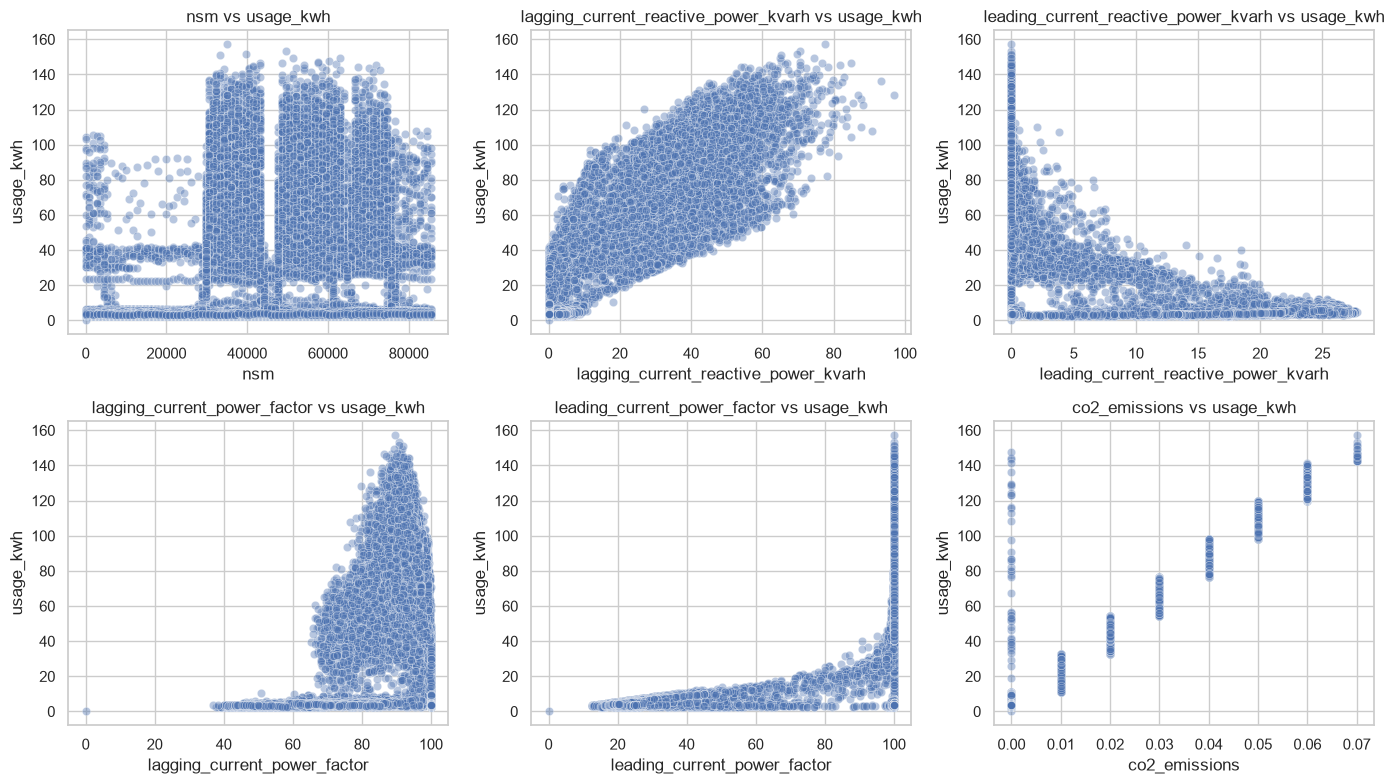

In [242]:
# Numerical Features vs Target (Scatter Plots using Subplots)

features = numerical_columns.copy()
features.remove("usage_kwh")

n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, column in enumerate(features):
    sns.scatterplot(
        data=df,
        x=column,
        y="usage_kwh",
        alpha=0.4,
        ax=axes[i]
    )

    axes[i].set_title(f"{column} vs usage_kwh")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("usage_kwh")

# Remove any unused subplots
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Scatter Plot Insights (`usage_kwh` vs Numerical Features)

- **nsm vs usage_kwh:** The relationship is weak with no clear linear trend, indicating that the time of day alone is not a strong predictor of energy consumption.

- **lagging_current_reactive_power_kvarh vs usage_kwh:** A strong positive relationship is observed, where higher lagging reactive power is associated with increased energy consumption.

- **leading_current_reactive_power_kvarh vs usage_kwh:** A weak negative relationship is present, with higher leading reactive power generally corresponding to lower energy usage.

- **lagging_current_power_factor vs usage_kwh:** A moderate positive trend is visible, suggesting that higher energy consumption is often associated with higher lagging power factor values.

- **leading_current_power_factor vs usage_kwh:** Most observations are concentrated near a power factor of 100, indicating a weak relationship despite a slight positive trend.

- **co2_emissions vs usage_kwh:** An almost perfect positive linear relationship exists, showing that CO₂ emissions increase proportionally with energy consumption.

### Regression Plots using Subplots

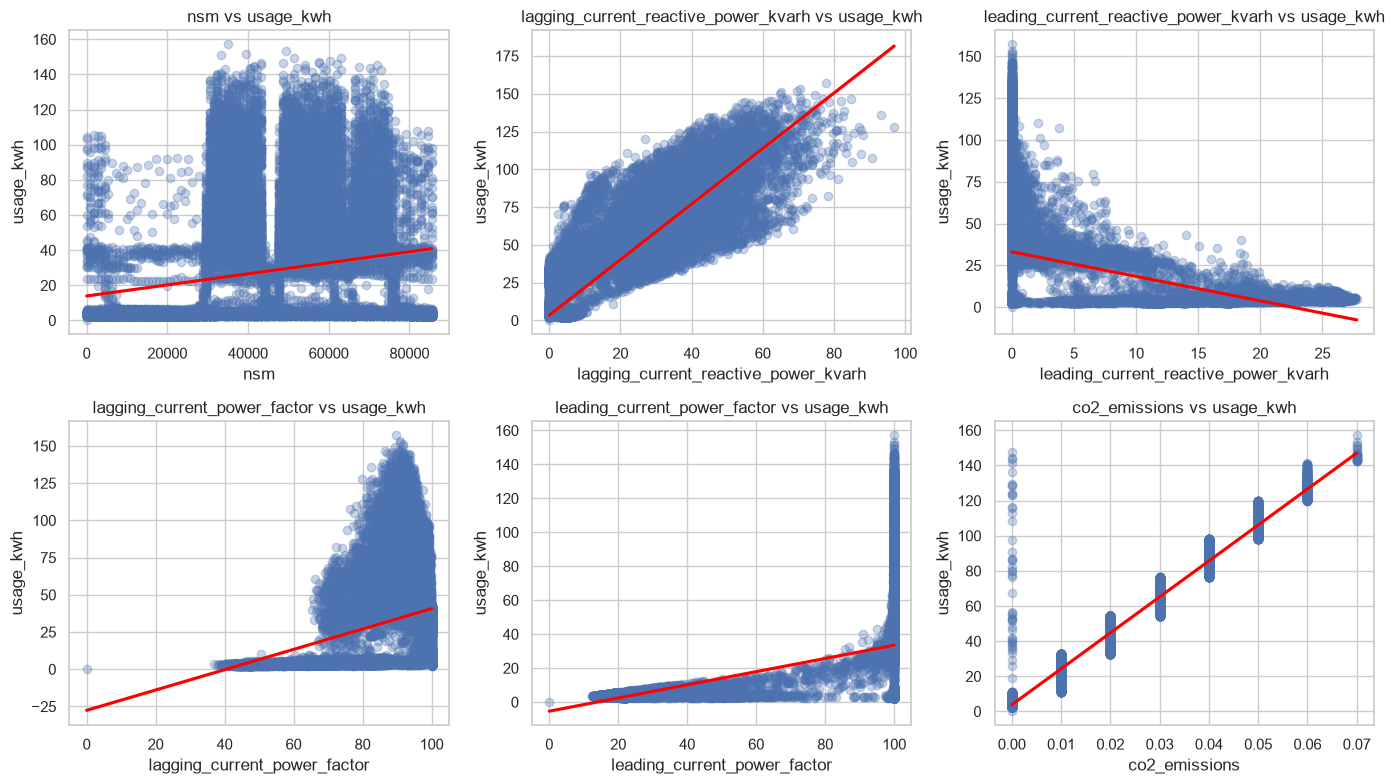

In [243]:
# Regression Plots using Subplots

features = numerical_columns.copy()
features.remove("usage_kwh")

n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, column in enumerate(features):
    sns.regplot(
        data=df,
        x=column,
        y="usage_kwh",
        scatter_kws={"alpha": 0.3},
        line_kws={"color": "red"},
        ax=axes[i]
    )

    axes[i].set_title(f"{column} vs usage_kwh")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("usage_kwh")

# Remove any unused subplots
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Regression Plot Insights (`usage_kwh` vs Numerical Features)

- **nsm vs usage_kwh:** The regression line shows a weak positive trend, indicating that energy consumption increases only slightly with the time of day.

- **lagging_current_reactive_power_kvarh vs usage_kwh:** A strong positive linear relationship is observed, making this one of the strongest predictors of energy consumption.

- **leading_current_reactive_power_kvarh vs usage_kwh:** The regression line has a negative slope, indicating that higher leading reactive power is generally associated with lower energy usage.

- **lagging_current_power_factor vs usage_kwh:** A moderate positive relationship is observed, suggesting that higher lagging power factor values are associated with increased energy consumption.

- **leading_current_power_factor vs usage_kwh:** The regression line indicates a weak positive trend, although the concentration of observations at a power factor of 100 limits the strength of the relationship.

- **co2_emissions vs usage_kwh:** The regression line demonstrates an almost perfect positive linear relationship, confirming that CO₂ emissions increase proportionally with energy consumption.

### Correlation Heatmap

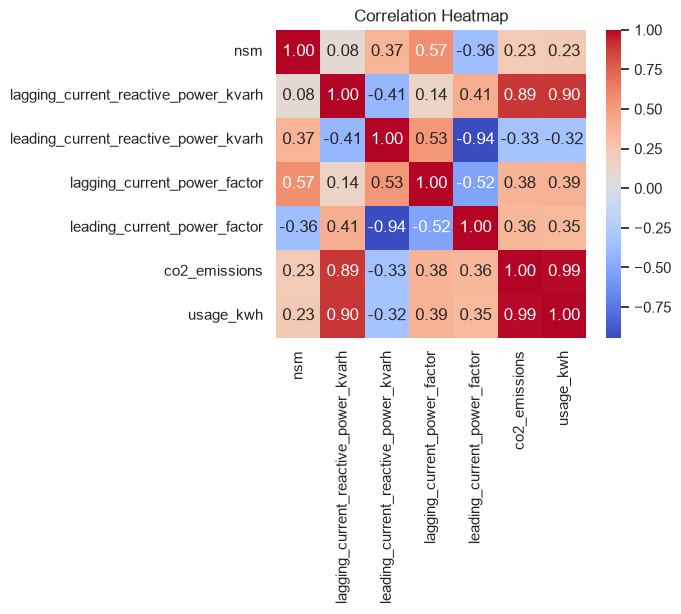

In [244]:
#Correlation Heatmap
plt.figure(figsize=(5,4))

sns.heatmap(
    df[numerical_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

Correlation Heatmap Insights

- **usage_kwh** has an almost perfect positive correlation with **co2_emissions (0.99)** and a very strong positive correlation with **lagging_current_reactive_power_kvarh (0.90)**, making them the strongest predictors of energy consumption.

- **leading_current_power_factor** and **leading_current_reactive_power_kvarh** exhibit a very strong negative correlation (**-0.94**), indicating an inverse relationship between these two electrical characteristics.

- **lagging_current_power_factor** shows a moderate positive correlation with **nsm (0.57)** and **leading_current_reactive_power_kvarh (0.53)**, but a moderate negative correlation with **leading_current_power_factor (-0.52)**.

- **co2_emissions** is strongly positively correlated with **lagging_current_reactive_power_kvarh (0.89)**, suggesting that higher reactive power consumption is associated with increased emissions.

- **nsm** has only weak correlations with **usage_kwh (0.23)** and **co2_emissions (0.23)**, indicating that the time of day has a limited influence on energy consumption.

- Overall, the heatmap indicates that **energy usage, CO₂ emissions, and lagging reactive power are closely related**, while the **leading electrical parameters tend to exhibit inverse relationships** with several other features.

### Load Type vs Energy Consumption

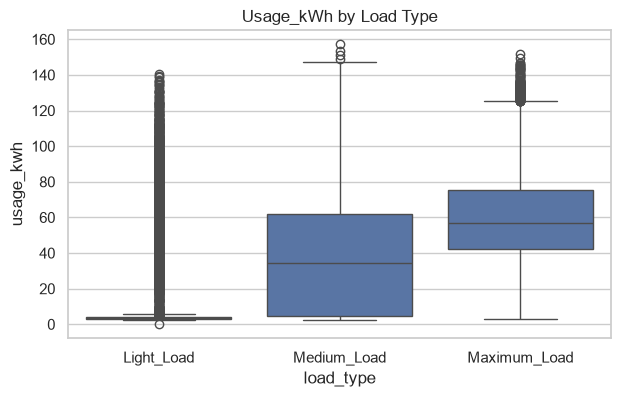

In [245]:
#Load Type vs Energy Consumption
plt.figure(figsize=(7,4))

sns.boxplot(
    data=df,
    x="load_type",
    y="usage_kwh"
)

plt.title("Usage_kWh by Load Type")

plt.show()

### Weekday vs Weekend

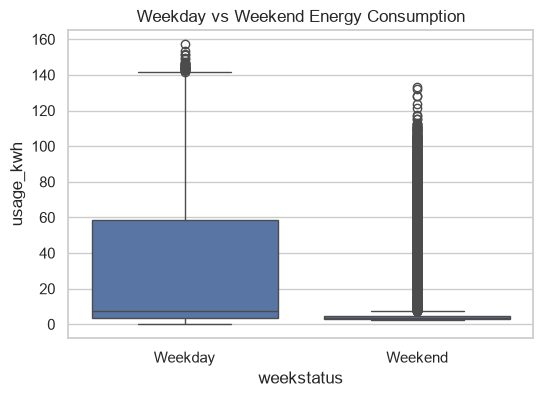

In [246]:
#Weekday vs Weekend
plt.figure(figsize=(6,4))

sns.boxplot(
    data=df,
    x="weekstatus",
    y="usage_kwh"
)

plt.title("Weekday vs Weekend Energy Consumption")

plt.show()

Weekday vs Weekend Energy Consumption Insights

- Energy consumption is generally **higher on weekdays** than on weekends, as indicated by the higher median and wider interquartile range.

- **Weekday** energy usage exhibits greater variability, suggesting more diverse operational loads during working days.

- **Weekend** energy consumption is concentrated at lower values, indicating reduced electricity usage during non-working days.

- Both categories contain **high-value outliers**, but weekday observations reach higher maximum energy consumption levels than weekends.

- Overall, the plot suggests that **operational activity and energy demand are significantly greater during weekdays** compared to weekends.

### Day of Week vs Energy Consumption

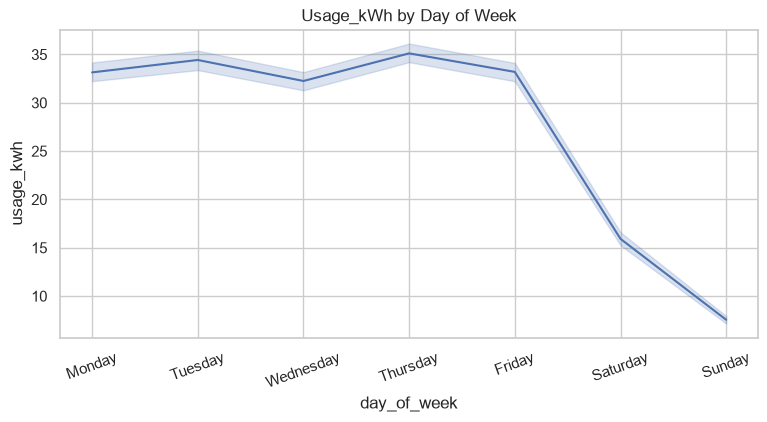

In [247]:
#Day of Week vs Energy Consumption
plt.figure(figsize=(9,4))

sns.lineplot(
    data=df,
    x="day_of_week",
    y="usage_kwh"
)
plt.title("Usage_kWh by Day of Week")
plt.xticks(rotation=20)
plt.show()


Energy Consumption by Day of the Week Insights

- **Weekdays (Monday–Friday)** generally exhibit higher median energy consumption and greater variability compared to weekends.

- **Thursday** shows the highest median energy usage among all days, indicating relatively higher operational demand.

- **Saturday** has lower energy consumption than weekdays but higher than **Sunday**, reflecting reduced yet ongoing activity.

- **Sunday** records the lowest median energy consumption, suggesting minimal operational load.

- All days contain **high-value outliers**, although weekdays consistently reach higher maximum energy consumption than weekends.

- Overall, the plot indicates that **energy demand is highest during weekdays and gradually decreases over the weekend**, consistent with typical industrial operating patterns.

### Energy Consumption Over Time

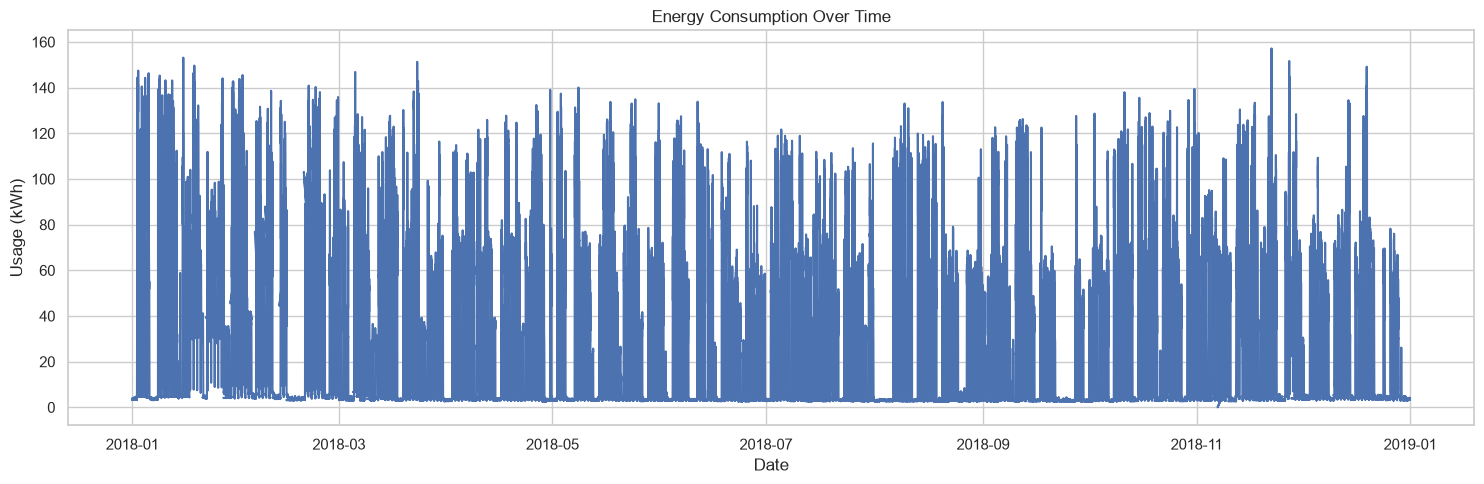

In [248]:
#Energy Consumption Over Time
plt.figure(figsize=(15,5))

plt.plot(df["date"], df["usage_kwh"])

plt.title("Energy Consumption Over Time")

plt.xlabel("Date")

plt.ylabel("Usage (kWh)")

plt.tight_layout()

plt.show()

Energy Consumption Over Time Insights

- Energy consumption fluctuates considerably throughout the year, indicating varying operational demand over time.

- Most observations remain at **low usage levels**, with intermittent spikes representing periods of high energy consumption.

- High energy consumption events occur throughout the year rather than being concentrated in a specific season, suggesting no strong seasonal trend.

- Several peaks exceed **150 kWh**, indicating occasional periods of maximum operational load.

- The time series does not exhibit a clear long-term increasing or decreasing trend, implying relatively stable energy usage patterns over the observed period.

- Overall, the plot suggests a **baseline of low energy consumption interrupted by frequent short-duration high-load events**, characteristic of intermittent industrial operations.

### Mean Energy Consumption

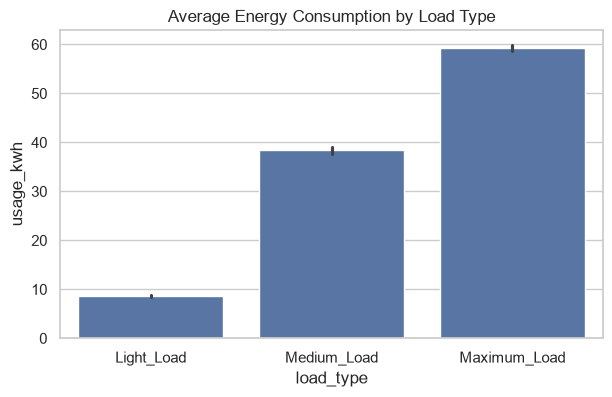

In [249]:
#Mean Energy Consumption
plt.figure(figsize=(7,4))

sns.barplot(
    data=df,
    x="load_type",
    y="usage_kwh",
    estimator="mean"
)

plt.title("Average Energy Consumption by Load Type")

plt.show()

Average Energy Consumption by Load Type Insights

- Average energy consumption increases consistently from **Light_Load** to **Medium_Load** and **Maximum_Load**, indicating that the load type accurately reflects energy demand.

- **Maximum_Load** records the highest average energy consumption, followed by **Medium_Load**, while **Light_Load** has the lowest average usage.

- The clear separation between the three categories suggests that **load_type** is a strong indicator of energy consumption.

- The small error bars indicate **low variability around the mean**, suggesting that the average energy consumption for each load category is stable.

- Overall, the plot confirms a strong positive relationship between **load intensity** and **energy consumption**.

## Multivariate Analysis

### Pair Plot

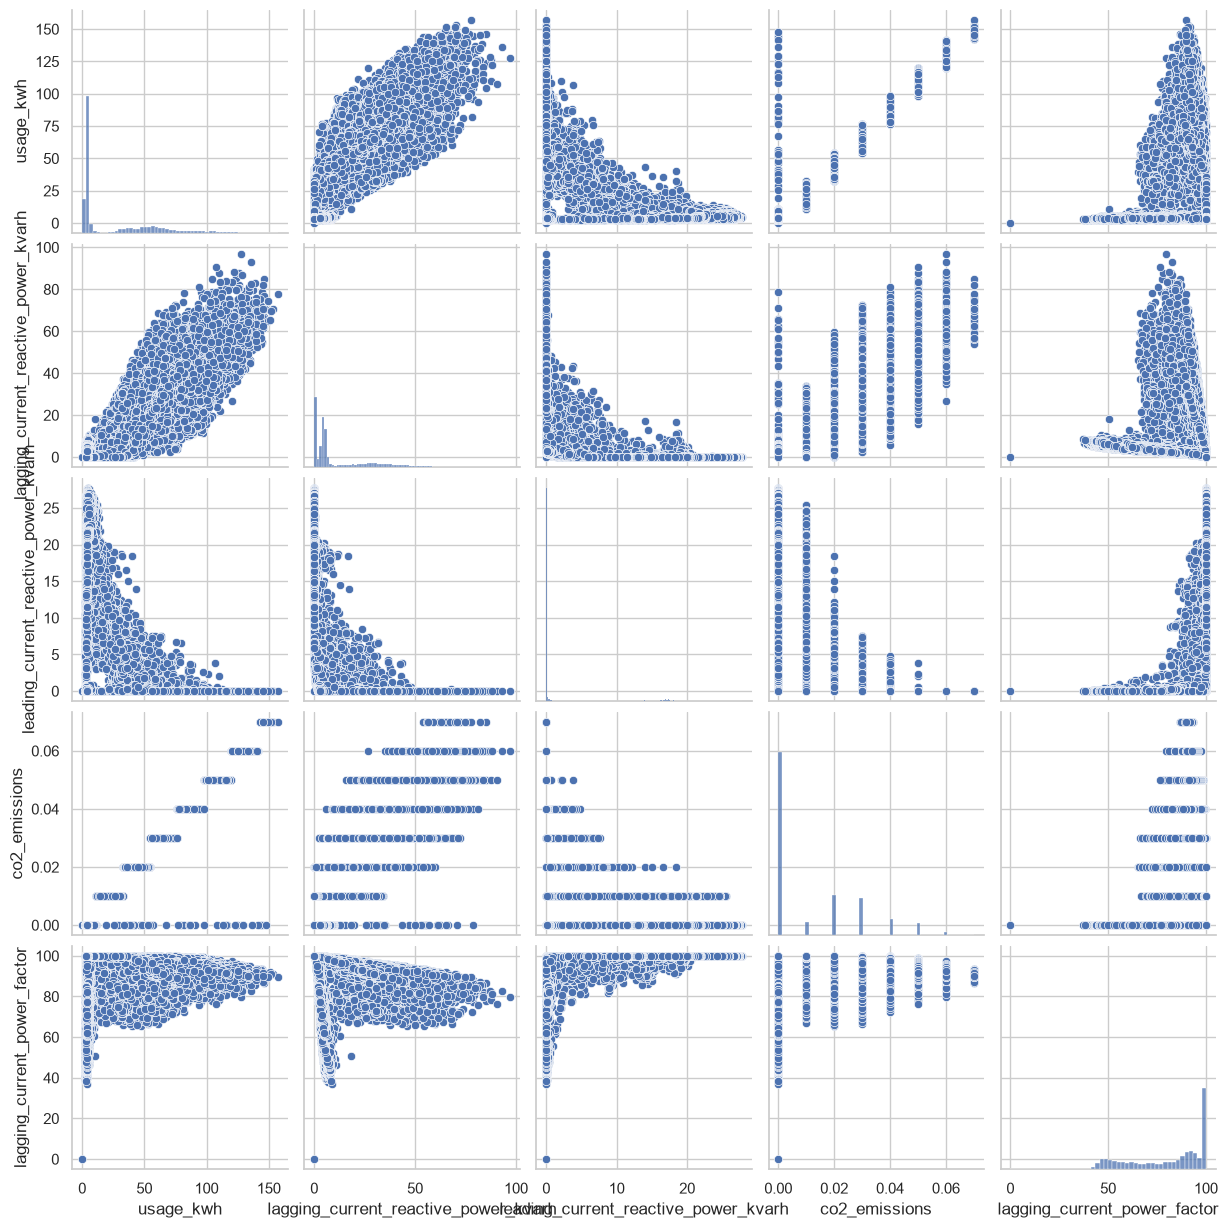

In [250]:
#Pair Plot
selected_features = [
    "usage_kwh",
    "lagging_current_reactive_power_kvarh",
    "leading_current_reactive_power_kvarh",
    "co2_emissions",
    "lagging_current_power_factor"
]

sns.pairplot(df[selected_features])

plt.show()

Pair Plot Insights

- **usage_kwh** shows a strong positive relationship with **lagging_current_reactive_power_kvarh** and **co2_emissions**, indicating these are the most influential numerical features.

- **usage_kwh** exhibits a weak negative relationship with **leading_current_reactive_power_kvarh**, where higher leading reactive power is generally associated with lower energy consumption.

- **co2_emissions** displays an almost perfect positive linear relationship with **usage_kwh**, suggesting emissions are directly proportional to energy usage.

- **lagging_current_reactive_power_kvarh** and **co2_emissions** are strongly positively correlated, indicating higher reactive power consumption is associated with increased emissions.

- **lagging_current_power_factor** shows a moderate positive relationship with **usage_kwh**, while **leading_current_reactive_power_kvarh** demonstrates an inverse relationship with the power factor.

- The diagonal distributions confirm that most numerical features are **non-normally distributed**, with noticeable skewness and the presence of high-value observations.

### Energy Consumption by Hour and Load Type

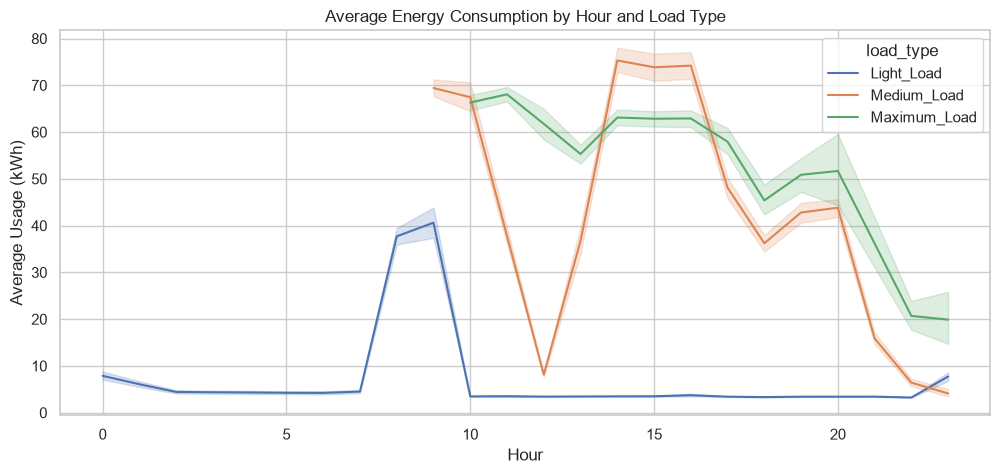

In [251]:
#Energy Consumption by Hour and Load Type
df["hour"] = df["date"].dt.hour

plt.figure(figsize=(12,5))

sns.lineplot(
    data=df,
    x="hour",
    y="usage_kwh",
    hue="load_type",
    estimator="mean"
)

plt.title("Average Energy Consumption by Hour and Load Type")

plt.xlabel("Hour")

plt.ylabel("Average Usage (kWh)")

plt.show()

Average Energy Consumption by Hour and Load Type Insights

- Average energy consumption varies significantly throughout the day, with distinct usage patterns observed across different load types.

- **Light_Load** maintains consistently low energy consumption throughout the day, with a brief increase during the morning hours.

- **Medium_Load** records the highest average energy consumption during the afternoon (around **14:00–16:00**), indicating peak operational activity.

- **Maximum_Load** exhibits sustained high energy consumption from late morning to evening, with its highest values occurring during the afternoon.

- Energy consumption for all load types declines noticeably during the late evening, reflecting reduced operational demand.

- Overall, the plot demonstrates that **energy usage is influenced by both the hour of the day and the operational load type**, with heavier loads consuming substantially more energy during peak working hours.

# Step 5: Outlier Detection & Treatment

The objective of this step is to identify extreme observations that may negatively impact model performance and determine an appropriate treatment strategy.

In [252]:
#Detect Outliers using IQR
def detect_outliers_iqr(data, columns):
    outlier_summary = []
    for column in columns:

        Q1 = data[column].quantile(0.25)
        Q3 = data[column].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = data[
            (data[column] < lower_bound) |
            (data[column] > upper_bound)
        ].shape[0]

        outlier_summary.append({
            "Feature": column,
            "Outliers": outliers,
            "Percentage": round((outliers / len(data)) * 100, 2)
        })

    return pd.DataFrame(outlier_summary).sort_values(
        by="Percentage",
        ascending=False
    )

outlier_summary = detect_outliers_iqr(df, numerical_columns)

outlier_summary

,Feature,Outliers,Percentage
4,leading_current_power_factor,8327,23.76
2,leading_current_reactive_power_kvarh,7759,22.14
1,lagging_current_reactive_power_kvarh,1059,3.02
5,co2_emissions,437,1.25
6,usage_kwh,328,0.94
0,nsm,0,0.00
3,lagging_current_power_factor,1,0.00


Observations

- The IQR method detected outliers in several numerical features.
- Two features, leading_current_power_factor (23.76%) and leading_current_reactive_power_kvarh (22.14%), showed a high percentage of outliers, suggesting that these values are likely part of the natural operating characteristics of the industrial process rather than data errors.
- lagging_current_reactive_power_kvarh, co2_emissions, and usage_kwh contained relatively few outliers.
- Since this dataset represents real-world industrial energy consumption, removing these observations could eliminate important operational scenarios and reduce the model's ability to generalize.
- Therefore, no outliers were removed during preprocessing. The impact of these observations will be evaluated during model training, and outlier treatment will only be considered if it improves model performance.

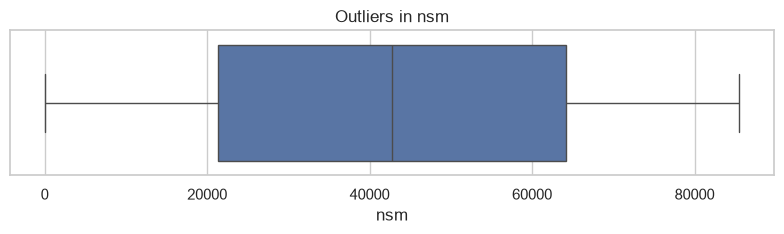

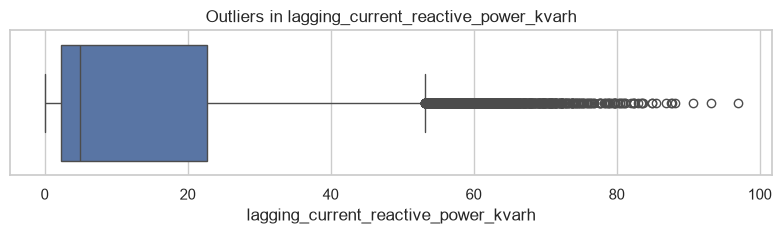

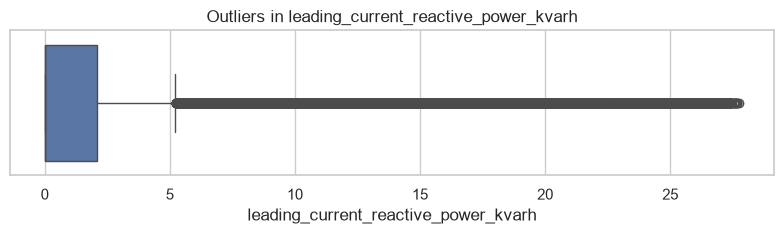

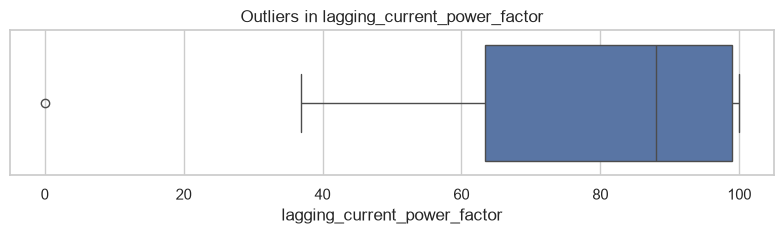

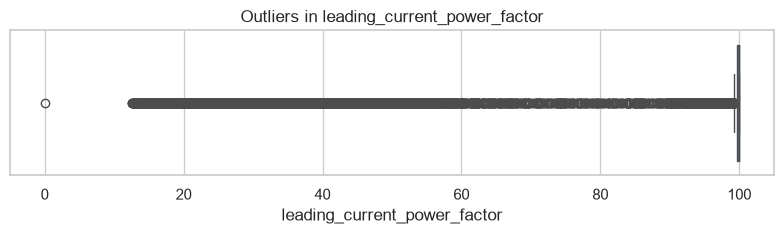

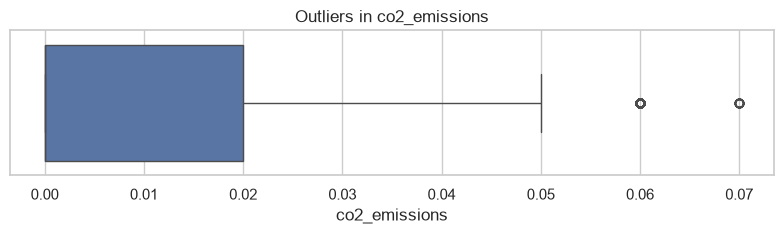

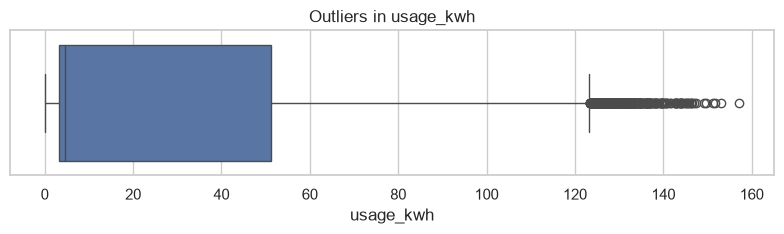

In [253]:
#Visualize Outliers
for column in numerical_columns:

    plt.figure(figsize=(8,2.5))

    sns.boxplot(x=df[column])

    plt.title(f"Outliers in {column}")

    plt.tight_layout()

    plt.show()

In [254]:
#Detect using Z-Score
from scipy.stats import zscore

z_scores = np.abs(zscore(df[numerical_columns]))

outliers = (z_scores > 3).sum(axis=0)

pd.DataFrame({
    "Feature": numerical_columns,
    "Outliers (Z > 3)": outliers
})

,Feature,Outliers (Z > 3)
0,nsm,0
1,lagging_current_reactive_power_kvarh,387
2,leading_current_reactive_power_kvarh,467
3,lagging_current_power_factor,1
4,leading_current_power_factor,0
5,co2_emissions,437
6,usage_kwh,212


Observations

- Outliers were evaluated using both the IQR and Z-score methods.
- The IQR method identified a substantially higher number of outliers for some features compared to the Z-score method.
- The discrepancy suggests that certain variables have naturally skewed distributions rather than erroneous observations.
- Since the dataset represents real industrial energy consumption, these extreme values are likely valid operating conditions.
- Therefore, no outliers were removed during preprocessing. Their impact will be assessed during model development, and alternative treatments (such as capping or robust models) may be evaluated if they improve predictive performance.

# Step 6: Feature Engineering

Feature Engineering involves creating new features from the existing data to improve the predictive performance of machine learning models.

In [255]:
# Extract datetime features

df["month"] = df["date"].dt.month
df["quarter"] = df["date"].dt.quarter

In [256]:
# Create season feature

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

df["season"] = df["month"].apply(get_season)

In [257]:
# Remove original datetime column

df.drop(columns="date", inplace=True)

In [258]:
df.head()

,weekstatus,day_of_week,nsm,load_type,lagging_current_reactive_power_kvarh,leading_current_reactive_power_kvarh,lagging_current_power_factor,leading_current_power_factor,co2_emissions,usage_kwh,hour,month,quarter,season
0,Weekday,Monday,900,Light_Load,2.95,0.00,73.21,100.00,0.00,3.17,0,1,1,Winter
1,Weekday,Monday,1800,Light_Load,4.46,0.00,66.77,100.00,0.00,4.00,0,1,1,Winter
2,Weekday,Monday,2700,Light_Load,3.28,0.00,70.28,100.00,0.00,3.24,0,1,1,Winter
3,Weekday,Monday,3600,Light_Load,3.56,0.00,68.09,100.00,0.00,3.31,1,1,1,Winter
4,Weekday,Monday,4500,Light_Load,4.50,0.00,64.72,100.00,0.00,3.82,1,1,1,Winter


In [259]:
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

df.info()

Rows    : 35040
Columns : 14
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 14 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   weekstatus                            35040 non-null  object 
 1   day_of_week                           35040 non-null  object 
 2   nsm                                   35040 non-null  int64  
 3   load_type                             35040 non-null  object 
 4   lagging_current_reactive_power_kvarh  35040 non-null  float64
 5   leading_current_reactive_power_kvarh  35040 non-null  float64
 6   lagging_current_power_factor          35040 non-null  float64
 7   leading_current_power_factor          35040 non-null  float64
 8   co2_emissions                         35040 non-null  float64
 9   usage_kwh                             35040 non-null  float64
 10  hour                                  35040 non-null 

In [260]:
# Numerical Features
numerical_columns = df.select_dtypes(include=["number"]).columns.tolist()

# Categorical Features
categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical Features:")
print(numerical_columns)

print("\nCategorical Features:")
print(categorical_columns)

Numerical Features:
['nsm', 'lagging_current_reactive_power_kvarh', 'leading_current_reactive_power_kvarh', 'lagging_current_power_factor', 'leading_current_power_factor', 'co2_emissions', 'usage_kwh', 'hour', 'month', 'quarter']

Categorical Features:
['weekstatus', 'day_of_week', 'load_type', 'season']


Observations

- Extracted the **month** and **quarter** from the `date` column to capture seasonal patterns in energy consumption.
- Created a new **season** feature by grouping months into four seasons.
- Removed the original `date` column after extracting the required temporal information.
- Avoided creating redundant features such as `year`, `day`, `minute`, and `week_of_year`, as they either contained no additional information or duplicated existing features like `hour` and `nsm`.
- The engineered dataset is now ready for the train-test split, followed by feature encoding and scaling.

# Step 7: Train-Test Split

The objective of this step is to split the dataset into training and testing sets before applying feature encoding and scaling. This helps prevent data leakage and provides an unbiased evaluation of the machine learning models.

In [261]:
# Features
X = df.drop(columns="usage_kwh")

# Target
y = df["usage_kwh"]

In [262]:
print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

Features Shape : (35040, 13)
Target Shape   : (35040,)


In [263]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

In [264]:
print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)

print("\nTraining Target :", y_train.shape)
print("Testing Target  :", y_test.shape)

Training Features : (28032, 13)
Testing Features  : (7008, 13)

Training Target : (28032,)
Testing Target  : (7008,)


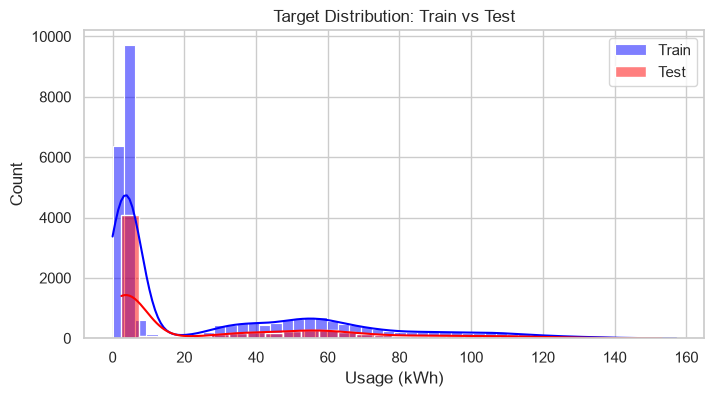

In [265]:
plt.figure(figsize=(8,4))

sns.histplot(y_train, kde=True, label="Train", color="blue", alpha=0.5)
sns.histplot(y_test, kde=True, label="Test", color="red", alpha=0.5)

plt.title("Target Distribution: Train vs Test")
plt.xlabel("Usage (kWh)")
plt.legend()

plt.show()

Observations

- The dataset was separated into features (`X`) and the target variable (`y`).
- An **80:20 train-test split** was performed using a fixed `random_state` to ensure reproducibility.
- The training dataset will be used to fit the machine learning models, while the testing dataset will be reserved for unbiased model evaluation.
- The target distribution was compared across both sets to ensure that the split did not introduce significant distributional differences.
- Feature encoding and scaling will be performed **after** the train-test split to prevent data leakage.

# Step 8: Data Preprocessing

The objective of this step is to prepare the training and testing datasets for machine learning by applying appropriate preprocessing techniques.

A ColumnTransformer is used to apply different transformations to numerical and categorical features while preventing data leakage.

In [266]:
# Numerical Features
numerical_columns = X_train.select_dtypes(
    include=["int64", "float64", "int32"]
).columns.tolist()

# Categorical Features
categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:")
print(numerical_columns)

print("\nCategorical Features:")
print(categorical_columns)

Numerical Features:
['nsm', 'lagging_current_reactive_power_kvarh', 'leading_current_reactive_power_kvarh', 'lagging_current_power_factor', 'leading_current_power_factor', 'co2_emissions', 'hour', 'month', 'quarter']

Categorical Features:
['weekstatus', 'day_of_week', 'load_type', 'season']


In [267]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_columns
        )
    ]
)

In [268]:
preprocessor.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_

In [269]:
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [270]:
print("Training Shape :", X_train_processed.shape)
print("Testing Shape  :", X_test_processed.shape)

Training Shape : (28032, 21)
Testing Shape  : (7008, 21)


In [271]:
import os

os.makedirs("../data/processed", exist_ok=True)

# Convert transformed arrays to DataFrames
X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=preprocessor.get_feature_names_out()
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=preprocessor.get_feature_names_out()
)

# Save
X_train_processed.to_csv("../dataset/processed/X_train_processed.csv", index=False)
X_test_processed.to_csv("../dataset/processed/X_test_processed.csv", index=False)

y_train.to_frame(name="usage_kwh").to_csv("../dataset/processed/y_train.csv", index=False)
y_test.to_frame(name="usage_kwh").to_csv("../dataset/processed/y_test.csv", index=False)

Summary

- Identified numerical and categorical features from the training dataset.
- Applied **StandardScaler** to normalize numerical features.
- Applied **OneHotEncoder** to convert categorical features into numerical representations.
- Combined both preprocessing steps using a **ColumnTransformer**.
- Fitted the preprocessing pipeline only on the training data to prevent data leakage.
- Transformed both the training and testing datasets using the fitted pipeline.
- Generated preprocessed datasets that are ready for model development in Sprint 2.